# 1.1 — Extra EDA on the cleaned dataset

`1.0-qp-eda-and-cleaning.ipynb` explored the raw data and built `retail-gap`. These checks look at the **cleaned** dataset, since that is
what the models train and are scored on. They only read `data/processed/retail-gap/` and the manifest, so they can be
re-run on their own.

1. Are train, val and test comparable after the grouped re-split?
2. Can a model tell gap images from full-shelf images **without looking at the shelf**? (the domain-shortcut risk)
3. Where are gaps, and what shape are they?
4. How much of an image is empty? (the number the restock rule will use)

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

from barcode.config import FIGURES_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR

FIG_DIR = FIGURES_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
SPLITS = ["train", "val", "test"]

%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DS = PROCESSED_DATA_DIR / "retail-gap"
manifest = pd.read_csv(INTERIM_DATA_DIR / "retail-gap" / "manifest.csv").set_index("file")
GRID_E = 104  # 4x4 px cells on a 416 px image, used for the union mask below


def image_row(split, path):
    im = Image.open(path)
    w, h = im.size
    rgb = np.asarray(im.convert("RGB").resize((160, 160)), dtype=np.float32)
    hsv = np.asarray(im.convert("RGB").resize((160, 160)).convert("HSV"), dtype=np.float32)
    grey = rgb.mean(axis=2)
    lap = (grey[1:-1, 1:-1] * 4 - grey[:-2, 1:-1] - grey[2:, 1:-1] - grey[1:-1, :-2] - grey[1:-1, 2:])
    return {"file": path.name, "split": split, "width": w, "height": h,
            "bytes_per_px": path.stat().st_size / (w * h),
            "brightness": grey.mean(), "contrast": grey.std(), "saturation": hsv[..., 1].mean(),
            "mean_r": rgb[..., 0].mean(), "mean_g": rgb[..., 1].mean(), "mean_b": rgb[..., 2].mean(),
            "sharpness": lap.var()}


def label_boxes(split, path):
    lab = DS / "labels" / split / path.with_suffix(".txt").name
    rows = [list(map(float, l.split()[1:])) for l in lab.read_text().splitlines() if l.strip()]
    return np.array(rows).reshape(-1, 4)  # cx, cy, w, h (normalised)


rows, box_list = [], []
for split in SPLITS:
    for p in tqdm(sorted((DS / "images" / split).glob("*.jpg")), desc=split):
        r = image_row(split, p)
        b = label_boxes(split, p)
        r["n_gaps"] = len(b)
        mask = np.zeros((GRID_E, GRID_E), bool)  # union of boxes, so overlapping gaps are not counted twice
        for cx, cy, bw, bh in b:
            x0, x1 = int(round((cx - bw / 2) * GRID_E)), int(round((cx + bw / 2) * GRID_E))
            y0, y1 = int(round((cy - bh / 2) * GRID_E)), int(round((cy + bh / 2) * GRID_E))
            mask[max(y0, 0):y1, max(x0, 0):x1] = True
        r["empty_share"] = mask.mean()
        rows.append(r)
        box_list += [dict(file=p.name, split=split, cx=cx, cy=cy, w=bw, h=bh) for cx, cy, bw, bh in b]

eda = pd.DataFrame(rows)
bx = pd.DataFrame(box_list)
is_sku = eda["file"].str.startswith("sku110k_")
eda["source"] = np.where(is_sku, "full shelf (SKU-110K)", eda["file"].map(manifest["scene"]))
eda["group"] = eda["file"].map(manifest["group"])
bx["source"] = bx["file"].map(eda.set_index("file")["source"])
bx["area"], bx["aspect"] = bx["w"] * bx["h"], bx["w"] / bx["h"]
print(len(eda), "images,", len(bx), "gap boxes")
eda["source"].value_counts()

3585 images, 17237 gap boxes


source
store                    3116
lab                       412
full shelf (SKU-110K)      57
Name: count, dtype: int64

### 1. Are the splits comparable?

The grouped split was stratified by scene, but the val/test sets are small (a few dozen full shelves and one lab shelf),
so a skew in difficulty could still hide in them. Compare what each split contains.

,store,lab,full shelf (SKU-110K),images,gaps/img (mean),gaps/img (median),empty share (mean),box area (median),brightness (mean)
split,,,,,,,,,
train,2822,377,40,3239,4.84,4.0,0.155,0.0181,92.900002
val,146,18,8,172,4.44,3.0,0.147,0.0178,93.000000
test,148,17,9,174,4.64,4.0,0.134,0.0178,92.000000


source,store %,lab %,full shelf (SKU-110K) %
split,,,
train,87.1,11.6,1.2
val,84.9,10.5,4.7
test,85.1,9.8,5.2


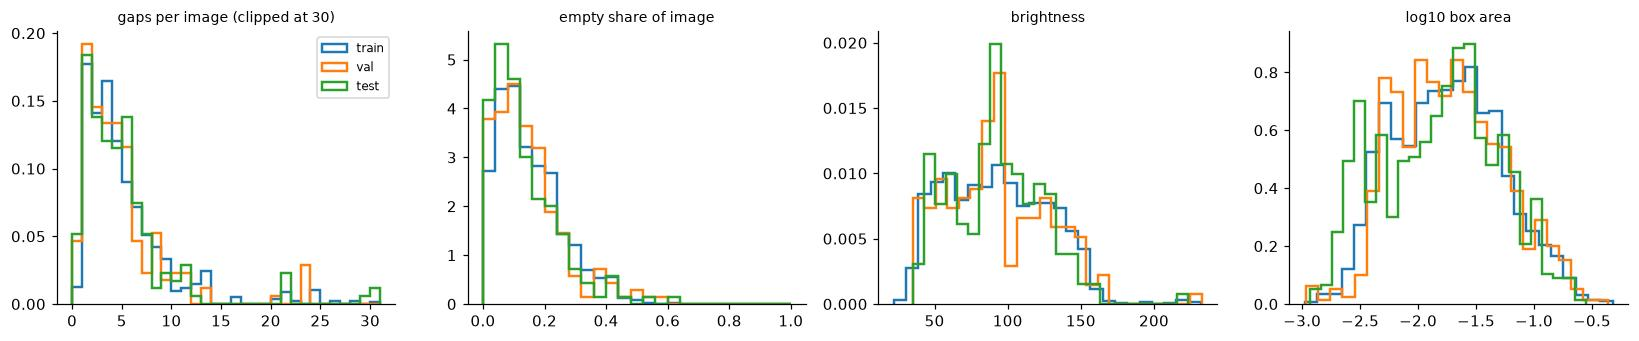

In [3]:
src_order = ["store", "lab", "full shelf (SKU-110K)"]
mix = pd.crosstab(eda["split"], eda["source"]).reindex(index=SPLITS, columns=src_order)
profile = pd.DataFrame({
    "images": eda.groupby("split").size(),
    "gaps/img (mean)": eda.groupby("split")["n_gaps"].mean().round(2),
    "gaps/img (median)": eda.groupby("split")["n_gaps"].median(),
    "empty share (mean)": eda.groupby("split")["empty_share"].mean().round(3),
    "box area (median)": bx.groupby("split")["area"].median().round(4),
    "brightness (mean)": eda.groupby("split")["brightness"].mean().round(1),
}).reindex(SPLITS)
display(pd.concat([mix, profile], axis=1))
display((mix.div(mix.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %"))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for split, c in zip(SPLITS, ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    d = eda[eda["split"] == split]
    axes[0].hist(d["n_gaps"].clip(upper=30), bins=np.arange(0, 32), density=True, histtype="step", color=c, lw=1.6, label=split)
    axes[1].hist(d["empty_share"], bins=np.linspace(0, 1, 26), density=True, histtype="step", color=c, lw=1.6)
    axes[2].hist(d["brightness"], bins=25, density=True, histtype="step", color=c, lw=1.6)
    axes[3].hist(np.log10(bx[bx["split"] == split]["area"]), bins=25, density=True, histtype="step", color=c, lw=1.6)
for ax, t in zip(axes, ["gaps per image (clipped at 30)", "empty share of image", "brightness", "log10 box area"]):
    ax.set_title(t, fontsize=9)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "split_profile.png", dpi=110)
plt.show()

**Observations**
- The splits are close on gaps per image, empty share, brightness and box size, so the grouped split did not make val or
  test noticeably easier or harder.
- The thin spots are the **full shelves** (single digits in val and test) and the **lab shelf**. A single missed gap on
  a full shelf is a false alarm with no true gaps to offset it, so report it as a separate line next to the overall mAP.

**Observations (continued)**
- Train is only 1.2% full shelves, while val and test are about 5% (8 and 9 images). The base rate of "no gap" images
  differs between train and evaluation, so false alarms on full shelves weigh more in val/test than the model saw in
  training.
- The test set has a slightly heavier tail of very small boxes, and val and test each contain a few lab images with 20+
  gaps (the right-hand bump in the first panel). Both are from the lab shelf.

### 2. Can a model tell the classes apart without looking at the shelf?

The gap images come from Roboflow (stretched to 416x416) and the full shelves from SKU-110K (phone photos, shrunk to at
most 640 px, original aspect). If simple image statistics already separate them, a detector can score well on
"no gap" images by recognising the **source** instead of an intact shelf.

Test: predict *gap image vs full-shelf image* from statistics alone, with grouped 5-fold cross-validation (copies of a
photo stay in the same fold). AUC 0.5 means no signal; 1.0 means the source is fully recognisable.

In [4]:
y = (~is_sku).astype(int).to_numpy()          # 1 = from the gap dataset, 0 = full shelf
groups = eda["group"].fillna(-1).astype(int).to_numpy()
groups = np.where(is_sku.to_numpy(), 10_000_000 + np.arange(len(eda)), groups)  # each SKU image is its own group

eda["aspect_ratio"] = eda["width"] / eda["height"]
FEATURE_SETS = {
    "image size only (width, height, aspect)": ["width", "height", "aspect_ratio"],
    "pixel statistics only (brightness, contrast, saturation, mean RGB)":
        ["brightness", "contrast", "saturation", "mean_r", "mean_g", "mean_b"],
    "file/texture only (JPEG bytes per pixel, sharpness)": ["bytes_per_px", "sharpness"],
    "everything except size": ["brightness", "contrast", "saturation", "mean_r", "mean_g", "mean_b",
                               "bytes_per_px", "sharpness"],
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
shortcut = {}
for name, cols in FEATURE_SETS.items():
    X = eda[cols].to_numpy()
    aucs = []
    for tr, te in cv.split(X, y, groups):
        m = GradientBoostingClassifier(random_state=SEED).fit(X[tr], y[tr])
        aucs.append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
    shortcut[name] = {"AUC (mean of 5 folds)": np.mean(aucs), "min fold": np.min(aucs)}
display(pd.DataFrame(shortcut).T.round(3))

cols = ["width", "height", "bytes_per_px", "brightness", "sharpness", "saturation"]
display(eda.groupby("source")[cols].median().round(2))

,AUC (mean of 5 folds),min fold
"image size only (width, height, aspect)",1.000,1.000
"pixel statistics only (brightness, contrast, saturation, mean RGB)",0.884,0.777
"file/texture only (JPEG bytes per pixel, sharpness)",1.000,1.000
everything except size,1.000,1.000


,width,height,bytes_per_px,brightness,sharpness,saturation
source,,,,,,
full shelf (SKU-110K),480.0,640.0,0.58,119.230003,4001.439941,67.059998
lab,416.0,416.0,0.12,109.870003,828.559998,48.939999
store,416.0,416.0,0.18,88.430000,1472.140015,89.720001


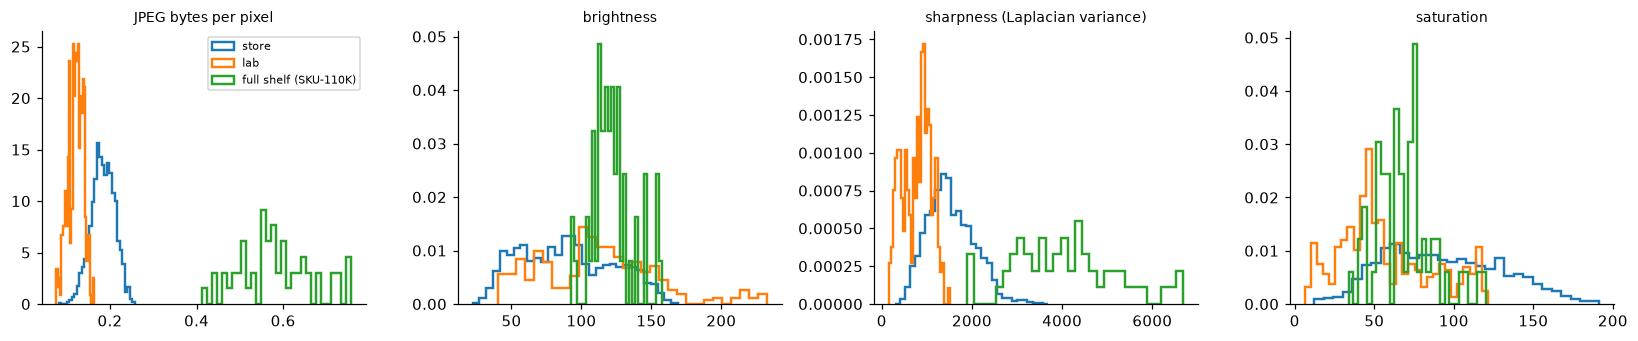

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
colors = {"store": "#1f77b4", "lab": "#ff7f0e", "full shelf (SKU-110K)": "#2ca02c"}
for s in src_order:
    d = eda[eda["source"] == s]
    for ax, col in zip(axes, ["bytes_per_px", "brightness", "sharpness", "saturation"]):
        ax.hist(d[col], bins=30, density=True, histtype="step", lw=1.6, color=colors[s], label=s)
for ax, t in zip(axes, ["JPEG bytes per pixel", "brightness", "sharpness (Laplacian variance)", "saturation"]):
    ax.set_title(t, fontsize=9)
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "source_shortcut.png", dpi=110)
plt.show()

**Observations**
- **The shortcut is real.** Image size alone separates gap images from full shelves perfectly (AUC 1.000): every gap
  image is 416x416, and none of the full shelves is. JPEG bytes per pixel and sharpness alone also reach AUC 1.000.
  Even plain colour and brightness statistics reach 0.88, because the SKU-110K shelves are brighter and more
  saturated.
- Part of this is **our own preprocessing**, not just the datasets: section 8 shrinks the SKU-110K images to at most
  640 px and saves them at JPEG quality 95, while the Roboflow images are 416x416 and about 3x smaller per pixel on disk (0.18 vs 0.58 bytes/px). A detector can learn
  "416x416 and small files mean gap" and ignore the shelf.
- **So the full-shelf (negative) scores are not yet trustworthy.** Precision and the false-alarm rate on full shelves
  may be too good. Because val/test hold only 8 and 9 full shelves, the effect on the headline mAP is small.
- Fix before relying on negatives: give the SKU-110K images the same treatment as the gap images (resize to
  416x416 with the same stretch, same JPEG quality) and re-run this check. The goal is AUC close to 0.5 on size and
  file statistics. The brightness difference is a genuine domain gap, so a second full-shelf source would still help.

### 3. Where are the gaps, and what do they look like?

Gap position and shape drive the modelling choices (input size, tiling, which gaps the model misses).

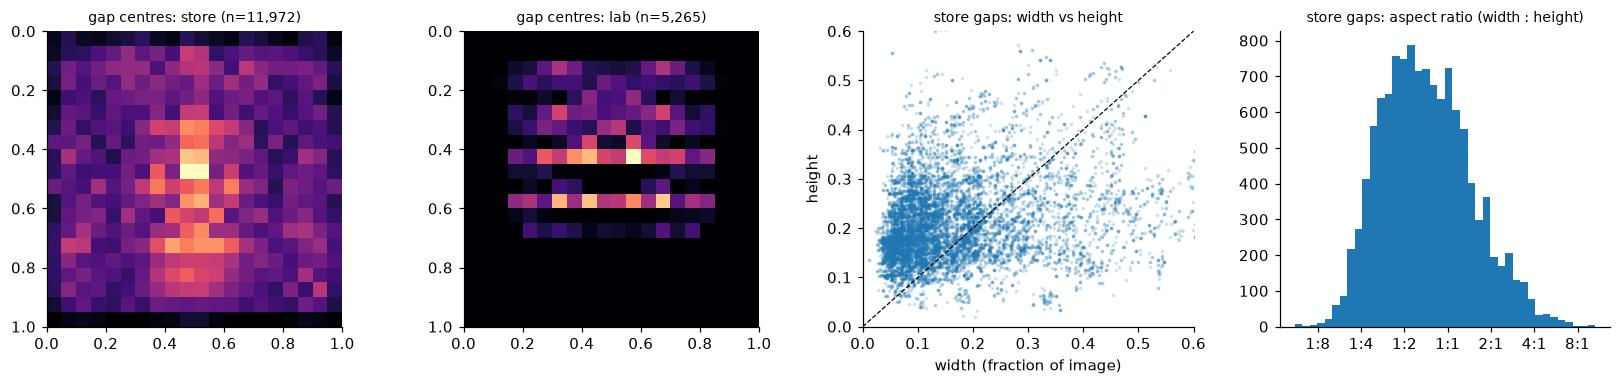

,boxes,area_median,area_p10,area_p90,share w/h<0.5,share w/h>2,share area<0.2%
source,,,,,,,
lab,5265,0.006,0.003,0.020,0.726,0.038,0.024
store,11972,0.027,0.009,0.096,0.346,0.085,0.000


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, s in zip(axes[:2], ["store", "lab"]):
    d = bx[bx["source"] == s]
    h = ax.hist2d(d["cx"], d["cy"], bins=20, range=[[0, 1], [0, 1]], cmap="magma")
    ax.invert_yaxis(); ax.set_aspect("equal")
    ax.set_title(f"gap centres: {s} (n={len(d):,})", fontsize=9)
d = bx[bx["source"] == "store"]
axes[2].scatter(d["w"], d["h"], s=2, alpha=0.15, color="#1f77b4")
axes[2].plot([0, 0.6], [0, 0.6], "k--", lw=0.8)
axes[2].set_xlim(0, 0.6); axes[2].set_ylim(0, 0.6)
axes[2].set_xlabel("width (fraction of image)"); axes[2].set_ylabel("height")
axes[2].set_title("store gaps: width vs height", fontsize=9)
axes[3].hist(np.log2(d["aspect"]), bins=40, color="#1f77b4")
axes[3].set_xticks([-3, -2, -1, 0, 1, 2, 3], ["1:8", "1:4", "1:2", "1:1", "2:1", "4:1", "8:1"])
axes[3].set_title("store gaps: aspect ratio (width : height)", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "gap_geometry.png", dpi=110)
plt.show()

geo = bx.groupby("source").agg(
    boxes=("area", "size"),
    area_median=("area", "median"), area_p10=("area", lambda s: s.quantile(0.1)), area_p90=("area", lambda s: s.quantile(0.9)),
    thin_vertical=("aspect", lambda s: (s < 0.5).mean()), wide=("aspect", lambda s: (s > 2).mean()),
    tiny=("area", lambda s: (s < 0.002).mean()),
).round(3)
geo.rename(columns={"thin_vertical": "share w/h<0.5", "wide": "share w/h>2", "tiny": "share area<0.2%"})

**Observations**
- **Store gaps** are spread over the whole shelf area, with a hot spot near the image centre. That reflects how the
  photos were framed, not where gaps tend to be.
- **Lab-shelf gaps** sit in a few fixed horizontal bands on one shelf unit, so the model can partly memorise their
  positions. This is another reason to report the store-only score as the headline number.
- Store gaps are mid-sized (median ~2.7% of the image, 10th to 90th percentile 0.9% to 9.6%) and most are not extreme in
  shape: about 35% are taller than twice their width and 9% wider than twice their height. Lab gaps are much smaller
  and 73% are thin vertical slots.
- The thin vertical slots are the gaps the YOLO predictions gave the lowest confidence (slide 10), so they are the first
  thing to check in the error analysis.

### 4. How much of an image is empty?

`empty_share` is the fraction of the image covered by the **union** of gap boxes (overlaps counted once). It is the
quantity a restock rule would threshold, and the same idea as the *error in % of shelf empty* metric used for the
baselines.

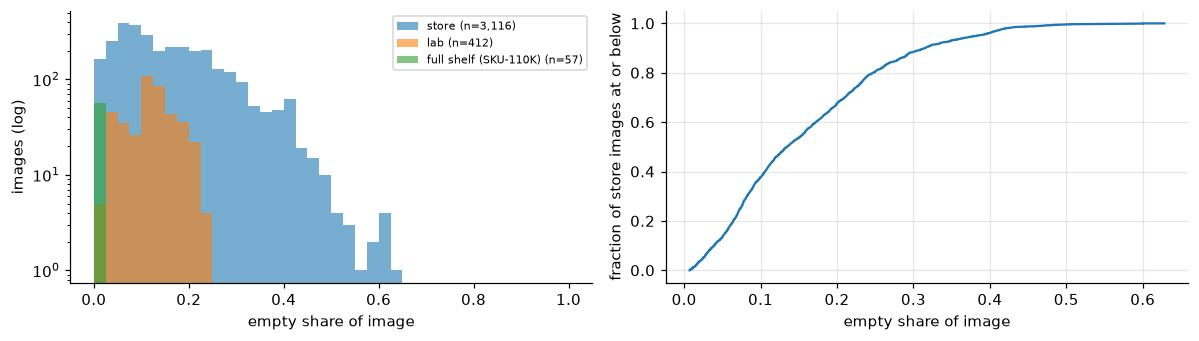

,count,mean,std,min,25%,50%,75%,90%,max
source,,,,,,,,,
full shelf (SKU-110K),57.0,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000
lab,412.0,0.121,0.05,0.007,0.094,0.121,0.154,0.191,0.234
store,3116.0,0.160,0.11,0.007,0.073,0.134,0.229,0.315,0.628


{'>5% empty': '86.6% of store images', '>10% empty': '62.2% of store images', '>20% empty': '32.4% of store images', '>30% empty': '11.6% of store images'}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for s in src_order:
    d = eda[eda["source"] == s]
    axes[0].hist(d["empty_share"], bins=np.linspace(0, 1, 41), alpha=0.6, color=colors[s], label=f"{s} (n={len(d):,})")
axes[0].set_yscale("log"); axes[0].set_xlabel("empty share of image"); axes[0].set_ylabel("images (log)")
axes[0].legend(fontsize=7)
d = eda[eda["source"] == "store"].sort_values("empty_share")
axes[1].plot(d["empty_share"], np.linspace(0, 1, len(d)), color="#1f77b4")
axes[1].set_xlabel("empty share of image"); axes[1].set_ylabel("fraction of store images at or below")
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "empty_share.png", dpi=110)
plt.show()

q = eda.groupby("source")["empty_share"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3)
display(q)
store = eda[eda["source"] == "store"]
print({f">{t:.0%} empty": f"{(store['empty_share'] > t).mean():.1%} of store images" for t in (0.05, 0.10, 0.20, 0.30)})

**Observations**
- Empty share is concentrated at low values: the median store image is about 13% empty, and 86.6% have more than 5%
  empty. Only 11.6% are more than 30% empty.
- Full shelves are exactly 0, and the lab shelf is narrow (median 12%, max 23%), so a restock threshold cannot be learned
  from the lab images.
- Because most photos already show noticeable empty space, a restock rule cannot just use "any gap found". It needs a
  threshold on empty share (for example 10%, 20% or 30%), chosen using the shares above and the cost of a missed
  restock vs. a false alarm.